# 01 Setup check and simulated calibration plane

Goal: prove Mitsuba (cuda_mono) and the authors' simulator run on the RTX 3090, then create the simulated calibration plane that every simulated measurement needs (`../data/calibration/plane_1.0m_sd0_TxFq_0_tilt_phong_0.19_0.81_46.91.rdm`). This mirrors the authors' `notebooks/CalPlaneGen.ipynb`.

In [1]:
%run ./00_common.ipynb

C:\Users\Rey\anaconda3\envs\kolb\Lib\site-packages\nbformat\validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


PROJECT  : C:\Users\Rey\Documents\Kolb_Radar_Project
FAKE_MODE: False
[mitsuba] Warning: Couldn't import the ipywidgets package. Installing this package is required for the system to properly log messages and print in Jupyter notebooks!


torch device: cuda
mitsuba variant: cuda_ad_rgb


Switched off Tx:  2
Switched off Rx:  10
torch 2.5.1+cu121 | device cuda
common ready


In [2]:
import mitsuba as mi, drjit as dr
print('mitsuba', mi.__version__, '| variant', mi.variant())
print('cuda available for torch:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
print('N_Tx, N_Rx, N_Fq =', sparams.mimo_system.get_param('N_Tx'), sparams.mimo_system.get_param('N_Rx'), sparams.mimo_system.get_param('N_Fq'))

mitsuba 3.3.0 | variant cuda_ad_rgb
cuda available for torch: True NVIDIA GeForce RTX 3090
N_Tx, N_Rx, N_Fq = 11 31 64


In [3]:
# Calibration plane, exactly the authors' settings (CalPlaneGen.ipynb)
(REPO / 'data' / 'calibration').mkdir(parents=True, exist_ok=True)
saved = dict(config)
config['material'] = 'phong'
config['phong_kd'] = 0.19
config['phong_ks'] = (1.0 - config['phong_kd'])
config['phong_ns'] = 46.91
config['N_Paths'] = 1000000
config['use_sms'] = False
config['cal_strat'] = 'simulated'
cal_file = Path(setup_utils.cal_path())
print('calibration file expected at', cal_file.resolve())
if not cal_file.exists():
    t0 = time.time()
    plane = scenes.OnePlane()
    msr = measurement.Simulated(plane)
    path = f"../data/calibration/plane_{config['N_Paths']/1000000}m_sd0_TxFq_{config['cal_tilt']}_tilt_{config['material']}_{config['phong_kd']}_{config['phong_ks']}_{config['phong_ns']}.rdm"
    utils.save_and_test(msr, path)
    print('calibration plane simulated in', round(time.time() - t0, 1), 's ->', path)
    if Path(path).resolve() != cal_file.resolve():
        print('WARNING: saved name differs from cal_path(); copying to the expected name')
        import shutil; shutil.copy(path, cal_file)
# restore the sphere material settings used by the paper's default config
for k in ('phong_kd', 'phong_ks', 'phong_ns'):
    config[k] = saved[k]
print('phong now', config['phong_kd'], config['phong_ks'], config['phong_ns'])

calibration file expected at C:\Users\Rey\Documents\Kolb_Radar_Project\InverseThzSim\data\calibration\plane_1.0m_sd0_TxFq_0_tilt_phong_0.19_0.81_46.91.rdm


Saved Successfully
calibration plane simulated in 14.5 s -> ../data/calibration/plane_1.0m_sd0_TxFq_0_tilt_phong_0.19_0.81_46.91.rdm
phong now 0.03 0.97 1200


In [4]:
# One test sphere: time it and look at the features
t0 = time.time()
test_p = np.array([0.0275, 0.0411, 0.3304, 0.02], dtype=np.float32)   # close to measured sphere position 4
m = simulate(test_p)
dt = time.time() - t0
feat = featurise(m)
print('one simulation + calibration:', round(dt, 2), 's | feature shape', feat.shape)
times = []
for i in range(5):
    t0 = time.time(); simulate(sample_params(1, np.random.default_rng(i))[0]); times.append(time.time() - t0)
print('5 more simulations, seconds each:', [round(t, 2) for t in times])
save_json({'seconds_per_sim': float(np.median(times)), 'feature_shape': list(feat.shape),
           'mitsuba_version': mi.__version__}, '01_setup.json')
log(f'01 done: {np.median(times):.2f} s per simulation')

one simulation + calibration: 6.54 s | feature shape (10, 31, 64)


5 more simulations, seconds each: [4.16, 4.02, 3.97, 4.01, 4.0]
saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\01_setup.json
2026-10-26 18:48:51  01 done: 4.01 s per simulation


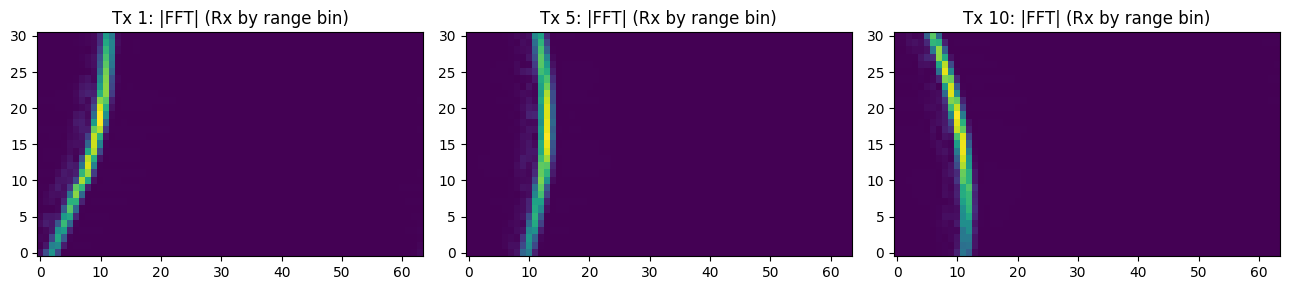

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(13, 3))
for i, t in enumerate([0, 4, 9]):
    ax[i].imshow(feat[t], aspect='auto', origin='lower'); ax[i].set_title(f'Tx {T_IDX[t]}: |FFT| (Rx by range bin)')
plt.tight_layout(); plt.savefig(FIGS / '01_example_features.png', dpi=120); plt.show()